# Analize *in vitro* TAM assay

In [2]:
import numpy as np
import pandas as pd
import gzip
from collections import Counter
from Bio.Seq import Seq
from Bio import SeqIO
import itertools
import matplotlib.pyplot as plt
import logomaker
import matplotlib
from matplotlib import rcParams
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.colors import ListedColormap
%matplotlib inline
%config InlineBackend.figure_format = 'png'
plt.rcParams['svg.fonttype'] = 'none'
matplotlib.rcParams['figure.dpi']= 300

In [7]:
variant_file = 'ISPmu1_TAM.fastq.gz'

In [27]:
variant_name = 'ISPmu1'

In [5]:
with gzip.open(variant_file, 'rt') as fin:
    variant_seqs = [record for record in SeqIO.parse(fin, 'fastq')]

In [6]:
len(variant_seqs)

245302

In [8]:
seq_before_TAM = 'CTGCTGAACCGCTCTTCCGATCTCCT'
seq_after_TAM = 'GCGCAGGTCACGAGGCATGCAAGCTTGGCTGTTTTG'

In [9]:
pos_start = [str(rec.seq).find(seq_before_TAM[-15:-5]) for rec in variant_seqs]

In [10]:
sum([x!=-1 for x in pos_start])

236529

In [11]:
pos_end = [str(rec.seq).find(seq_after_TAM[0:10]) for rec in variant_seqs]

In [12]:
sum([x!=-1 for x in pos_end])

99467

In [13]:
complete = [pos_end[i]!=-1 and pos_start[i]!=-1 for i in range(len(pos_end))]

In [14]:
sum(complete)

94494

In [15]:
complete_pos = [pos_end[i]-pos_start[i]-len(seq_before_TAM[-15:-5]) for i in range(len(complete)) if complete[i]]

In [16]:
complete_pos_series = pd.Series(Counter(complete_pos)).sort_values(ascending=False)[0:10]
complete_pos_series

30    15382
31     6295
32     5717
36     5477
41     5079
35     4519
27     4358
33     3307
29     2594
34     2225
dtype: int64

In [17]:
good_range = [29,30,31,32,33]
background_range = [34,35,36]

In [18]:
complete_len = [pos_end[i]-pos_start[i]-len(seq_before_TAM[-15:-5]) in good_range for i in range(len(pos_end))]
complete_len_bkg = [pos_end[i]-pos_start[i]-len(seq_before_TAM[-15:-5]) in background_range for i in range(len(pos_end))]

In [19]:
sum(complete_len)

33456

In [20]:
TAMs = [str(variant_seqs[i].seq[pos_end[i]-8:pos_end[i]].reverse_complement()) for i in range(len(complete_len))
        if complete_len[i] and complete[i]]
background = [str(variant_seqs[i].seq[pos_end[i]-8:pos_end[i]].reverse_complement()) for i in range(len(complete_len))
        if complete_len_bkg[i] and complete[i]]

In [21]:
TAMs = [TAM for TAM in TAMs if 'N' not in TAM]

In [22]:
len(TAMs)

33295

In [23]:
print(f'# reads: {len(variant_seqs)}')
print('# complete reads: {} ({:.1f}% of total reads)'.format(sum(complete), 100*sum(complete)/len(variant_seqs)))
print('# TAM reads: {} ({:.1f}% of complete reads)'.format(len(TAMs), 100*len(TAMs)/sum(complete)))
print('# background reads: {} ({:.1f}% of complete reads)'.format(len(background), 100*len(background)/sum(complete)))

# reads: 245302
# complete reads: 94494 (38.5% of total reads)
# PAM reads: 33295 (35.2% of complete reads)
# background reads: 12221 (12.9% of complete reads)


In [24]:
f_background_read = len(background)/len(TAMs)

## Sequence logo

In [25]:
def make_freq_df(seqs):
    counters = [Counter() for i in range(len(seqs[0]))]
    for i in range(len(counters)):
        for seq in seqs:
            counters[i][seq[i]] +=1
    freqs = pd.DataFrame(counters).fillna(0)
    freqs = freqs.divide(freqs.sum(axis=1), axis=0)
    return freqs

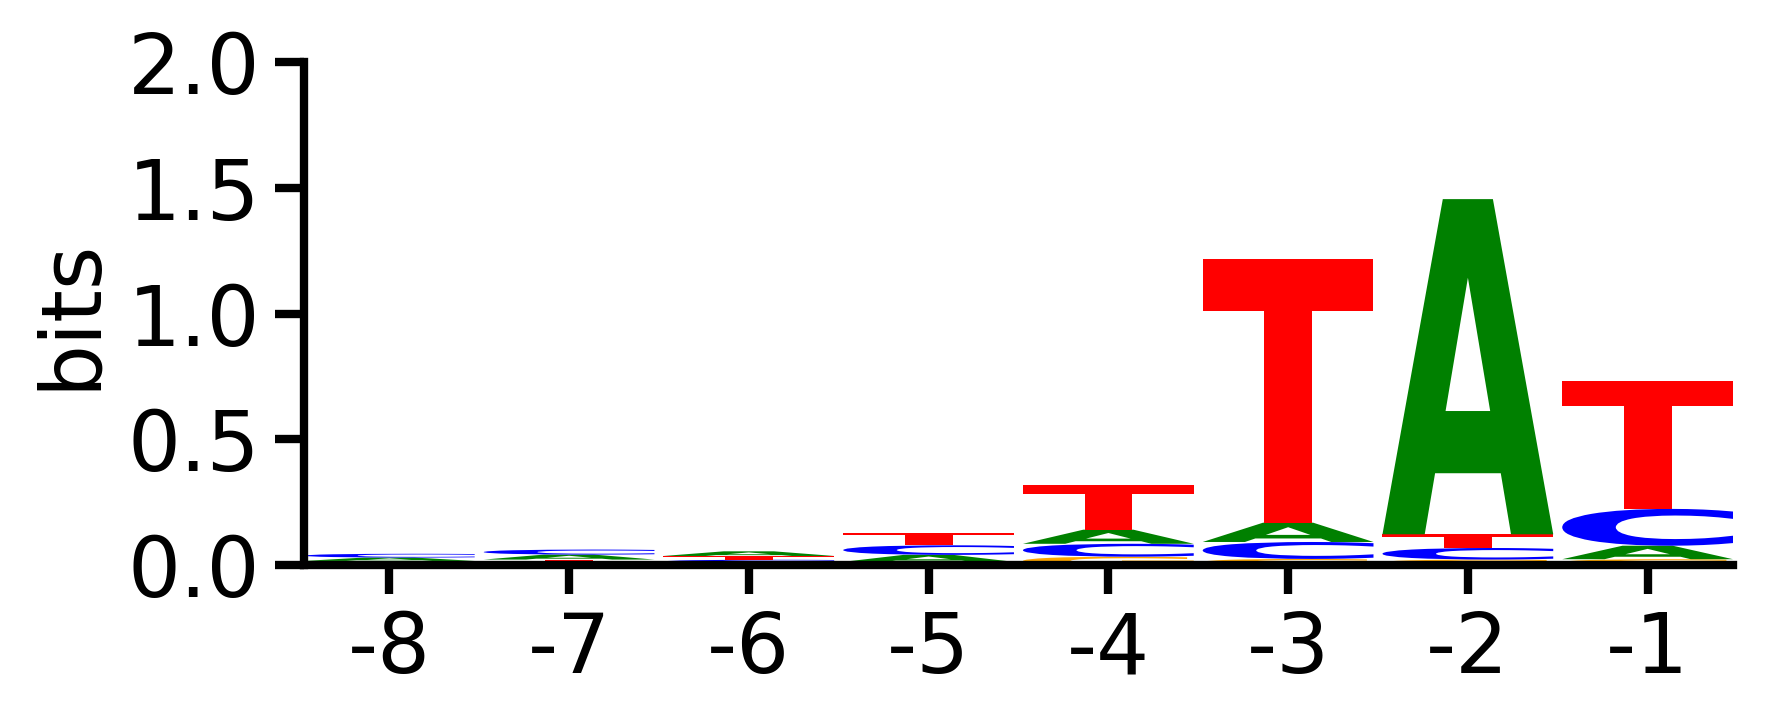

In [29]:
# normalize frequency df
normalized_freq_df = make_freq_df(TAMs)[list('ATGC')].subtract(f_background_read*make_freq_df(background)[list('ATGC')]).clip(0)
normalized_freq_df = normalized_freq_df.divide(normalized_freq_df.sum(axis=1), axis=0)

# create Logo object
seq_info = logomaker.transform_matrix(normalized_freq_df, from_type='probability', to_type='information')
seq_logo = logomaker.Logo(seq_info, figsize=(6,2.5))

# style using Logo methods
seq_logo.style_spines(visible=False)
seq_logo.style_spines(spines=['left', 'bottom'], visible=True)
seq_logo.style_xticks(fmt='%d', anchor=0)
seq_logo.ax.set_xticklabels(np.arange(-8,0), size=20)

for y in seq_logo.ax.get_yticklabels():
    y.set_size(20)
    
seq_logo.ax.spines['bottom'].set_linewidth(2)
seq_logo.ax.spines['left'].set_linewidth(2)

seq_logo.ax.tick_params(width=2, length=7)
seq_logo.ax.set_ylim(0,2)

# style using Axes methods
seq_logo.ax.set_ylabel("bits", size=20)
#plt.title(variant_name, size=20, pad=10)
plt.tight_layout()
#plt.savefig('Logos/{}_in_vitro_TAM.svg'.format(variant_name))
plt.show()

### Compute TAM frequencies

In [30]:
TAM_counts = Counter(TAMs)

In [31]:
counts_df = pd.DataFrame.from_dict(dict(TAM_counts), columns=['Count'], orient='index')

In [32]:
counts_df.shape

(12055, 1)

In [33]:
# get missing sequences
missing_seqs = [''.join(seq) for seq in itertools.product(['A','G','T','C'], repeat=8) if ''.join(seq) not in counts_df.index]
len(missing_seqs)

53481

In [34]:
missing_seqs_df = pd.DataFrame({'Count':[0]*len(missing_seqs)}, index=missing_seqs)
counts_df_full = pd.concat([counts_df, missing_seqs_df])

In [35]:
# pseudocounts
pseudocount = 1
counts_df_full['Count'] = counts_df_full['Count'].add(pseudocount)

In [36]:
def all_TAM_frequencies(library):
    """
    Given a library of random sequence counts, returns frequencies for all possible TAMs
    """
    TAM_len = len(library.index[0])
    all_TAMs = [''.join(x) for x in itertools.product(['A','G','T','C','N'], repeat=TAM_len)]
    # make TAM dictionary
    TAM_dictionary = {}
    for TAM in all_TAMs:
        nN = TAM.count('N')
        if nN != 0 and nN != len(TAM):
            TAM_dictionary[TAM] = [TAM.replace('N', '{}').format(*it) for it in itertools.product(['A','G','T','C'], repeat=nN)]
            TAM_dictionary[TAM] = [TAM for TAM in TAM_dictionary[TAM] if TAM in library.index]
    # make TAM count dataframe list
    TAM_counts_by_n_N = [library[['Count']]]
    # fill it
    for i in range(1,TAM_len):
        # compute counts of TAMs with i Ns from counts of TAMs with i-1 Ns
        print('Computing counts for TAMs of length {}'.format(TAM_len-i))
        all_TAMs_i_N = [TAM for TAM in all_TAMs if TAM.count('N')==i]
        library_TAM_i_N = {}
        for TAM in all_TAMs_i_N:
            library_TAM_i_N[TAM] = library.loc[TAM_dictionary[TAM],'Count'].sum()
        TAM_counts_by_n_N.append(pd.DataFrame.from_dict(library_TAM_i_N, orient='index', columns=['Count']))
    # concatenate them and compute frequencies
    all_TAMs_df = [df.assign(Frequency=df['Count'].divide(library['Count'].sum()).values) for df in TAM_counts_by_n_N]
    return all_TAMs_df

In [37]:
all_TAMs_df = all_TAM_frequencies(counts_df_full)

Computing counts for PAMs of length 7
Computing counts for PAMs of length 6
Computing counts for PAMs of length 5
Computing counts for PAMs of length 4
Computing counts for PAMs of length 3
Computing counts for PAMs of length 2
Computing counts for PAMs of length 1


In [53]:
all_TAMs_df_cc = pd.concat(all_TAMs_df)

### Compute background frequencies

In [39]:
background_counts = Counter(background)

In [40]:
counts_df = pd.DataFrame.from_dict(dict(background_counts), columns=['Count'], orient='index')

In [41]:
counts_df.shape

(8240, 1)

In [42]:
# get missing sequences
missing_seqs = [''.join(seq) for seq in itertools.product(['A','G','T','C'], repeat=8) if ''.join(seq) not in counts_df.index]
len(missing_seqs)

57296

In [43]:
missing_seqs_df = pd.DataFrame({'Count':[0]*len(missing_seqs)}, index=missing_seqs)
counts_df_full = pd.concat([counts_df, missing_seqs_df])

In [44]:
# pseudocounts
pseudocount = 1
counts_df_full['Count'] = counts_df_full['Count'].add(pseudocount)

In [45]:
all_background_df = all_TAM_frequencies(counts_df_full)

Computing counts for PAMs of length 7
Computing counts for PAMs of length 6
Computing counts for PAMs of length 5
Computing counts for PAMs of length 4
Computing counts for PAMs of length 3
Computing counts for PAMs of length 2
Computing counts for PAMs of length 1


In [46]:
base_TAM_freqs = pd.concat(all_background_df)

### Compute enrichment

In [48]:
def compute_lrf(cut, base):
    lrf = {}
    TAM_len = len(cut.index[0])
    
    for i in range(1,TAM_len+1):
        TAMs = [indx for indx in cut.index if indx.count('N')==TAM_len-i]
        lrf[i] = np.log10(cut.loc[TAMs, 'Frequency']/base.loc[TAMs, 'Frequency'])
        lrf[i] = lrf[i][np.isfinite(lrf[i])]
    return lrf

In [57]:
lrf = compute_lrf(all_TAMs_df_cc, base_TAM_freqs)

In [58]:
def make_TAM_array(TAM_dfs, rowpos, colpos):
    '''
    colpos must come before rowpos
    '''
    n_specified_bases = len(rowpos)+len(colpos)
    data = TAM_dfs[n_specified_bases].apply(lambda x: x if x > 0 else 0)
    array = []
    rowidx = [it for it in itertools.product(['A','G','T','C'], repeat=len(rowpos))]
    colidx = [it for it in itertools.product(['A','G','T','C'], repeat=len(colpos))]
    for ri in rowidx:
        new_row = []
        for ci in colidx:
            TAM = ['N']*8
            for i in rowpos+colpos:
                TAM[i] = '{}'
            TAM = ''.join(TAM).format(*ci, *ri)
            new_row.append(data[TAM])
        array.append(new_row)
    return np.array(array), [''.join(i) for i in rowidx], [''.join(i) for i in colidx]  

In [59]:
def heatmap(data, row_labels, col_labels, colbarperc, xsize, ysize, lwd, ax=None,
            cbar_kw={}, cbarlabel="", **kwargs):

    if not ax:
        ax = plt.gca()

    # Plot the heatmap
    im = ax.imshow(data, **kwargs)

    # Create colorbar
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="{}%".format(colbarperc), pad=0.05) #2
    plt.colorbar(im, cax=cax, **cbar_kw)

    # We want to show all ticks...
    ax.set_xticks(np.arange(data.shape[1]))
    ax.set_yticks(np.arange(data.shape[0]))
    # ... and label them with the respective list entries.
    ax.set_xticklabels(['\n'.join(list(l)) for l in col_labels])
    ax.set_yticklabels([' '.join(list(l)) for l in row_labels])

    # Let the horizontal axes labeling appear on top.
    ax.tick_params(top=True, bottom=False,
                   labeltop=True, labelbottom=False)

    # Rotate the tick labels and set their alignment.
    plt.setp(ax.get_xticklabels(), size=xsize, family='monospace') #3
    plt.setp(ax.get_yticklabels(), size=ysize, family='monospace') #2.5

    # Turn spines off and create white grid.
    for edge, spine in ax.spines.items():
        spine.set_visible(False)

    ax.set_xticks(np.arange(data.shape[1]+1)-.5, minor=True)
    ax.set_yticks(np.arange(data.shape[0]+1)-.5, minor=True)
    ax.grid(which="minor", color="w", linestyle='-', linewidth=lwd) # .2
    ax.tick_params(which="minor", bottom=False, left=False)

    return im

In [60]:
def make_TAM_heatmap(lrf, rowpos, colpos):
    heatmap_data, rowidx, colidx = make_TAM_array(lrf, rowpos, colpos)
    
    # get figsize, lbarperc, xsize, ysize, lwd
    ny = len(rowpos)
    nx = len(colpos)
    fgs = (6+nx, 6+ny)
    colbarperc = 3
    xsize_d = {'4':3, '3':6, '2':10, '1':10}
    ysize_d = {'4':2.5, '3':6, '2':10, '1':10}
    xsize = xsize_d[str(nx)]
    ysize = ysize_d[str(ny)]
    lwd = 13 / max(nx,ny)**3
    
    fig, ax = plt.subplots(figsize=fgs)
    im = heatmap(heatmap_data, rowidx, colidx, colbarperc, xsize, ysize, lwd,
                       ax=ax, cmap="Blues")
    fig.tight_layout()
    plt.show()

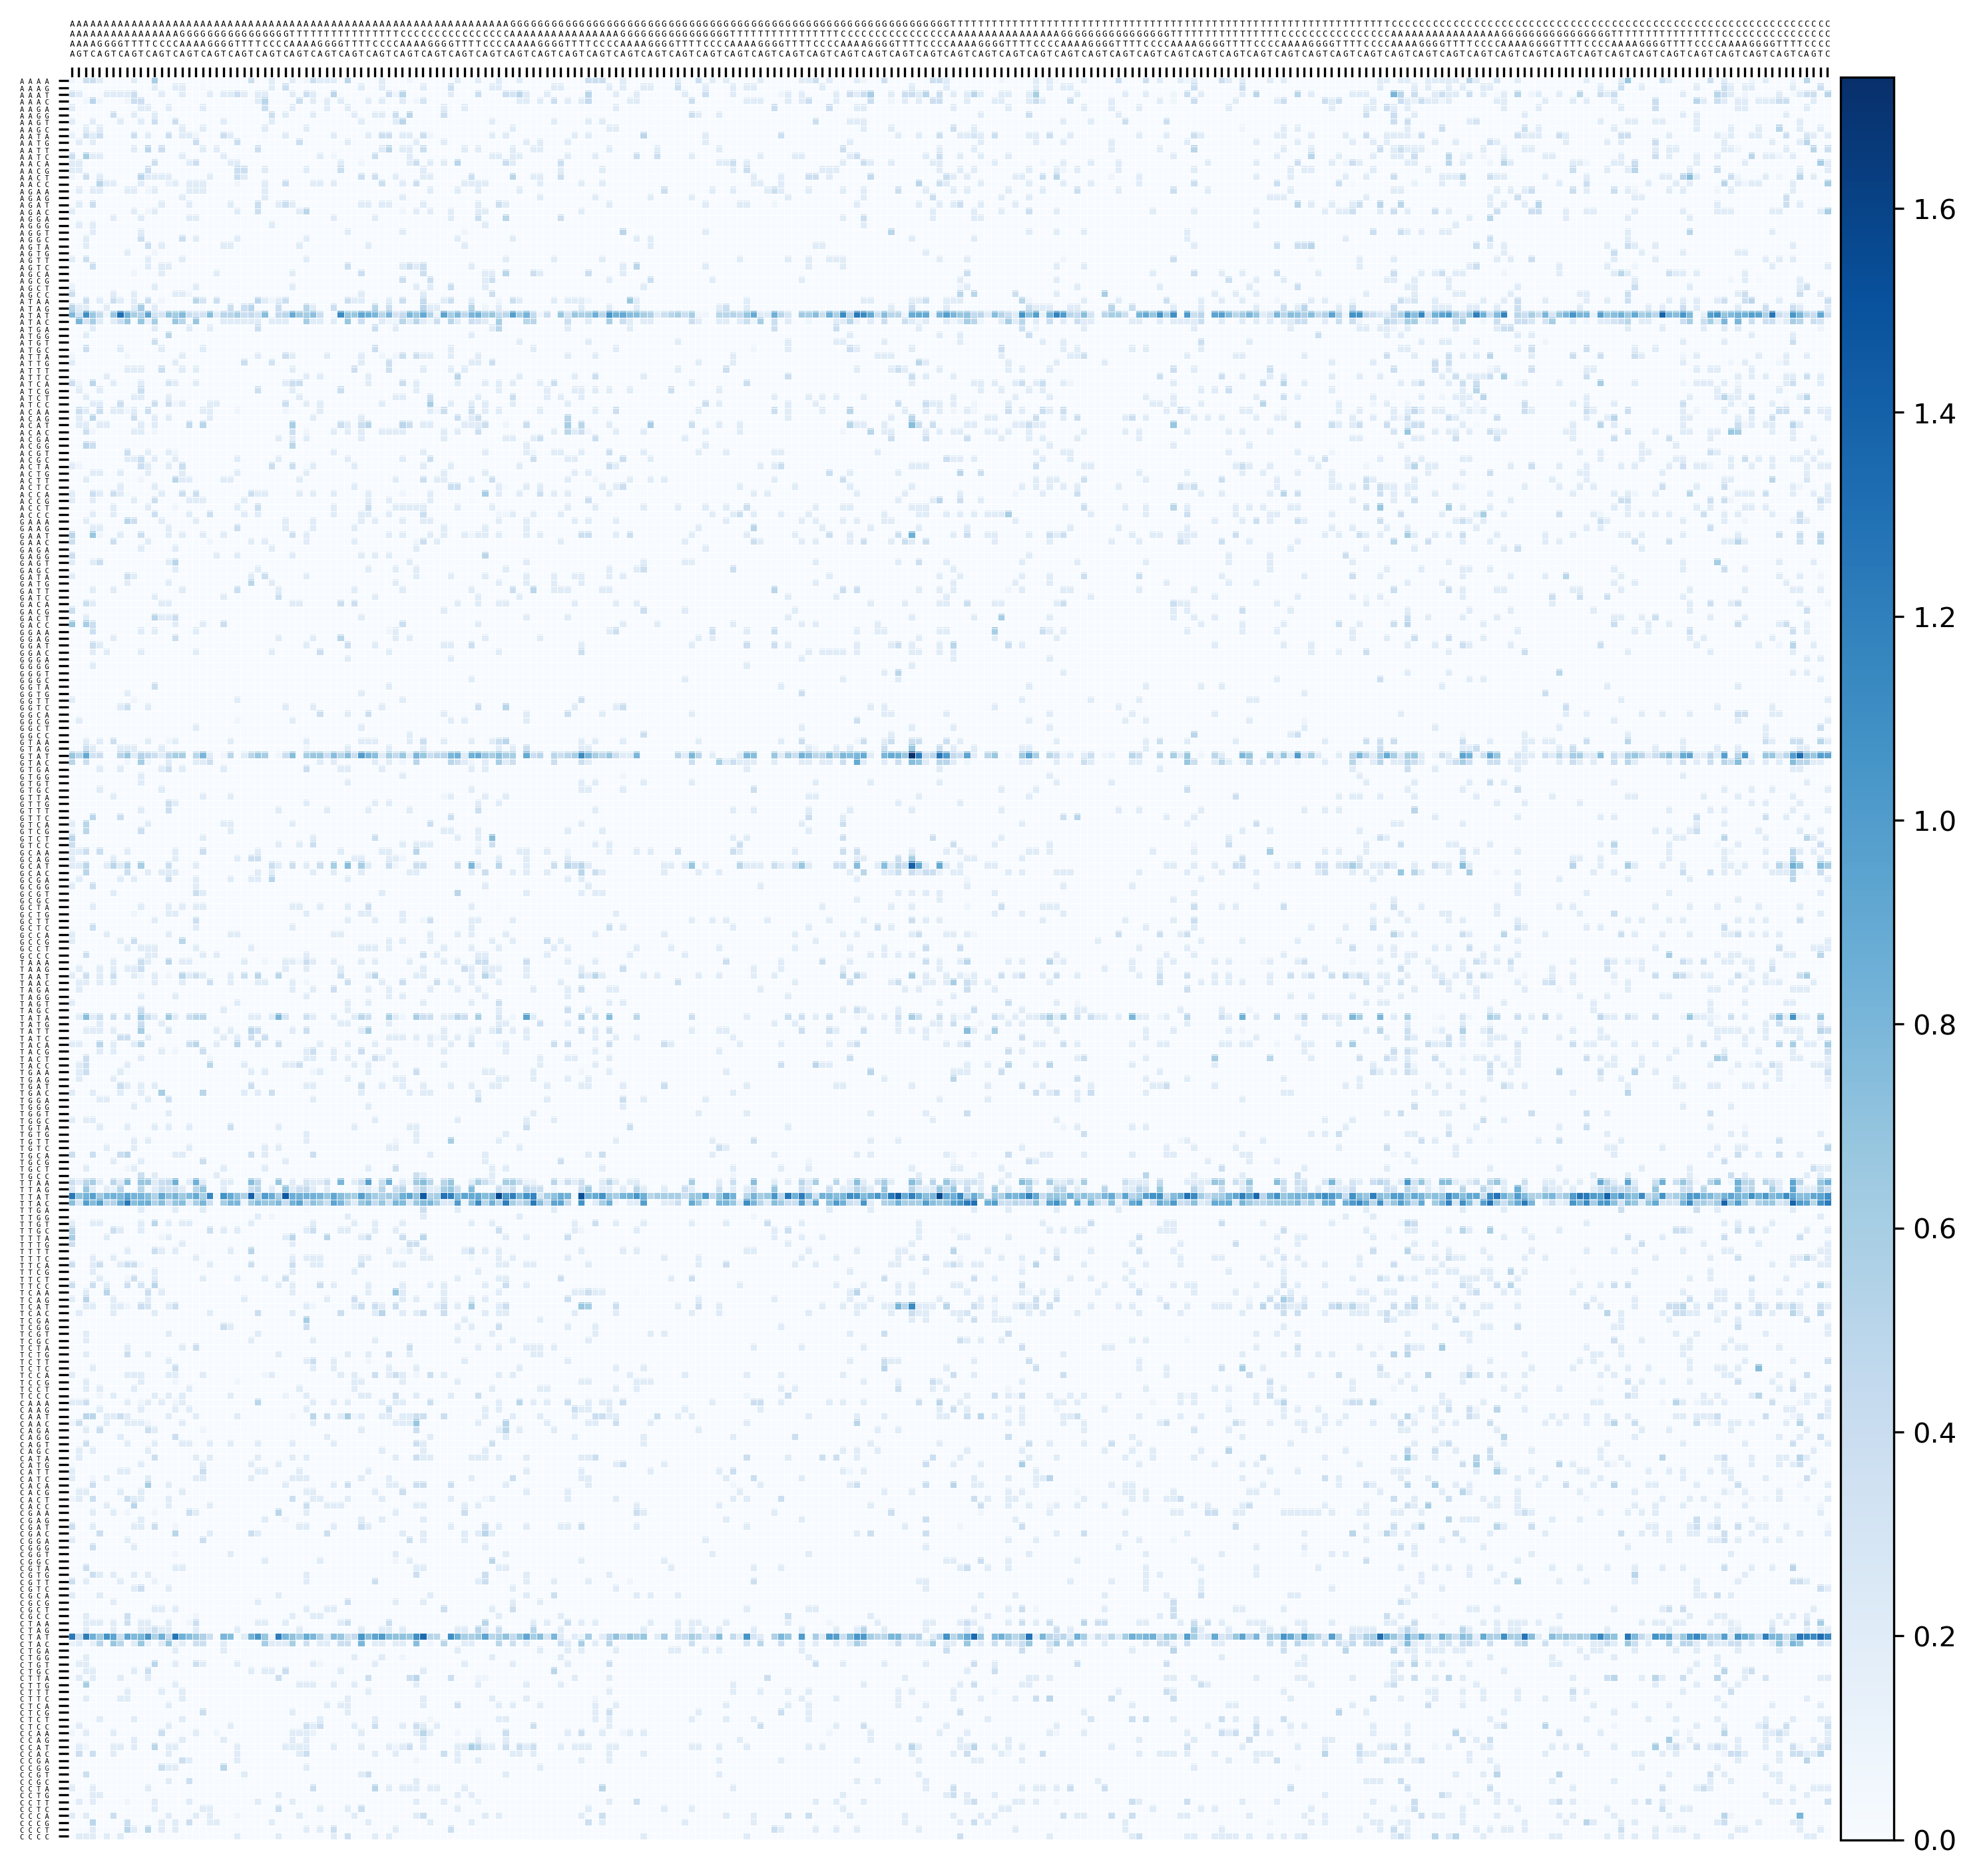

In [61]:
make_TAM_heatmap(lrf, [4,5,6,7], [0,1,2,3])

In [62]:
def reorder_data(data):
    t_data = data.transpose()
    new_rows = []
    for row in t_data:
        reordered = [row[4*j+i] for i in range(4) for j in range(4)]
        new_rows.append(reordered)
    new_rows = np.array(new_rows).transpose()
    new_cols = []
    for col in new_rows:
        reordered = [col[4*j+i] for i in range(4) for j in range(4)]
        new_cols.append(reordered)
    return np.array(new_cols).transpose()

### Pretty heatmap

In [75]:
heatmap_df = pd.DataFrame(heatmap_data)
heatmap_df.index = rowidx
heatmap_df.columns = colidx

In [76]:
rowpos, colpos = [6,7], [4,5]

In [77]:
heatmap_data, rowidx, colidx = make_TAM_array(lrf, rowpos, colpos)

to_int = {'A':0, 'T':1, 'C':2, 'G':3}

to_base = {to_int[k]:k for k in to_int}

col_anno = pd.DataFrame([[to_int[i] for i in list(idx)] for idx in colidx]).transpose()

row_anno = pd.DataFrame([[to_int[i] for i in list(idx)] for idx in rowidx])

base_colormap = ListedColormap(["lightgreen", "tomato", "lightskyblue", "lemonchiffon"])

In [78]:
heatmap_df = pd.DataFrame(heatmap_data)
heatmap_df.index = rowidx
heatmap_df.columns = colidx

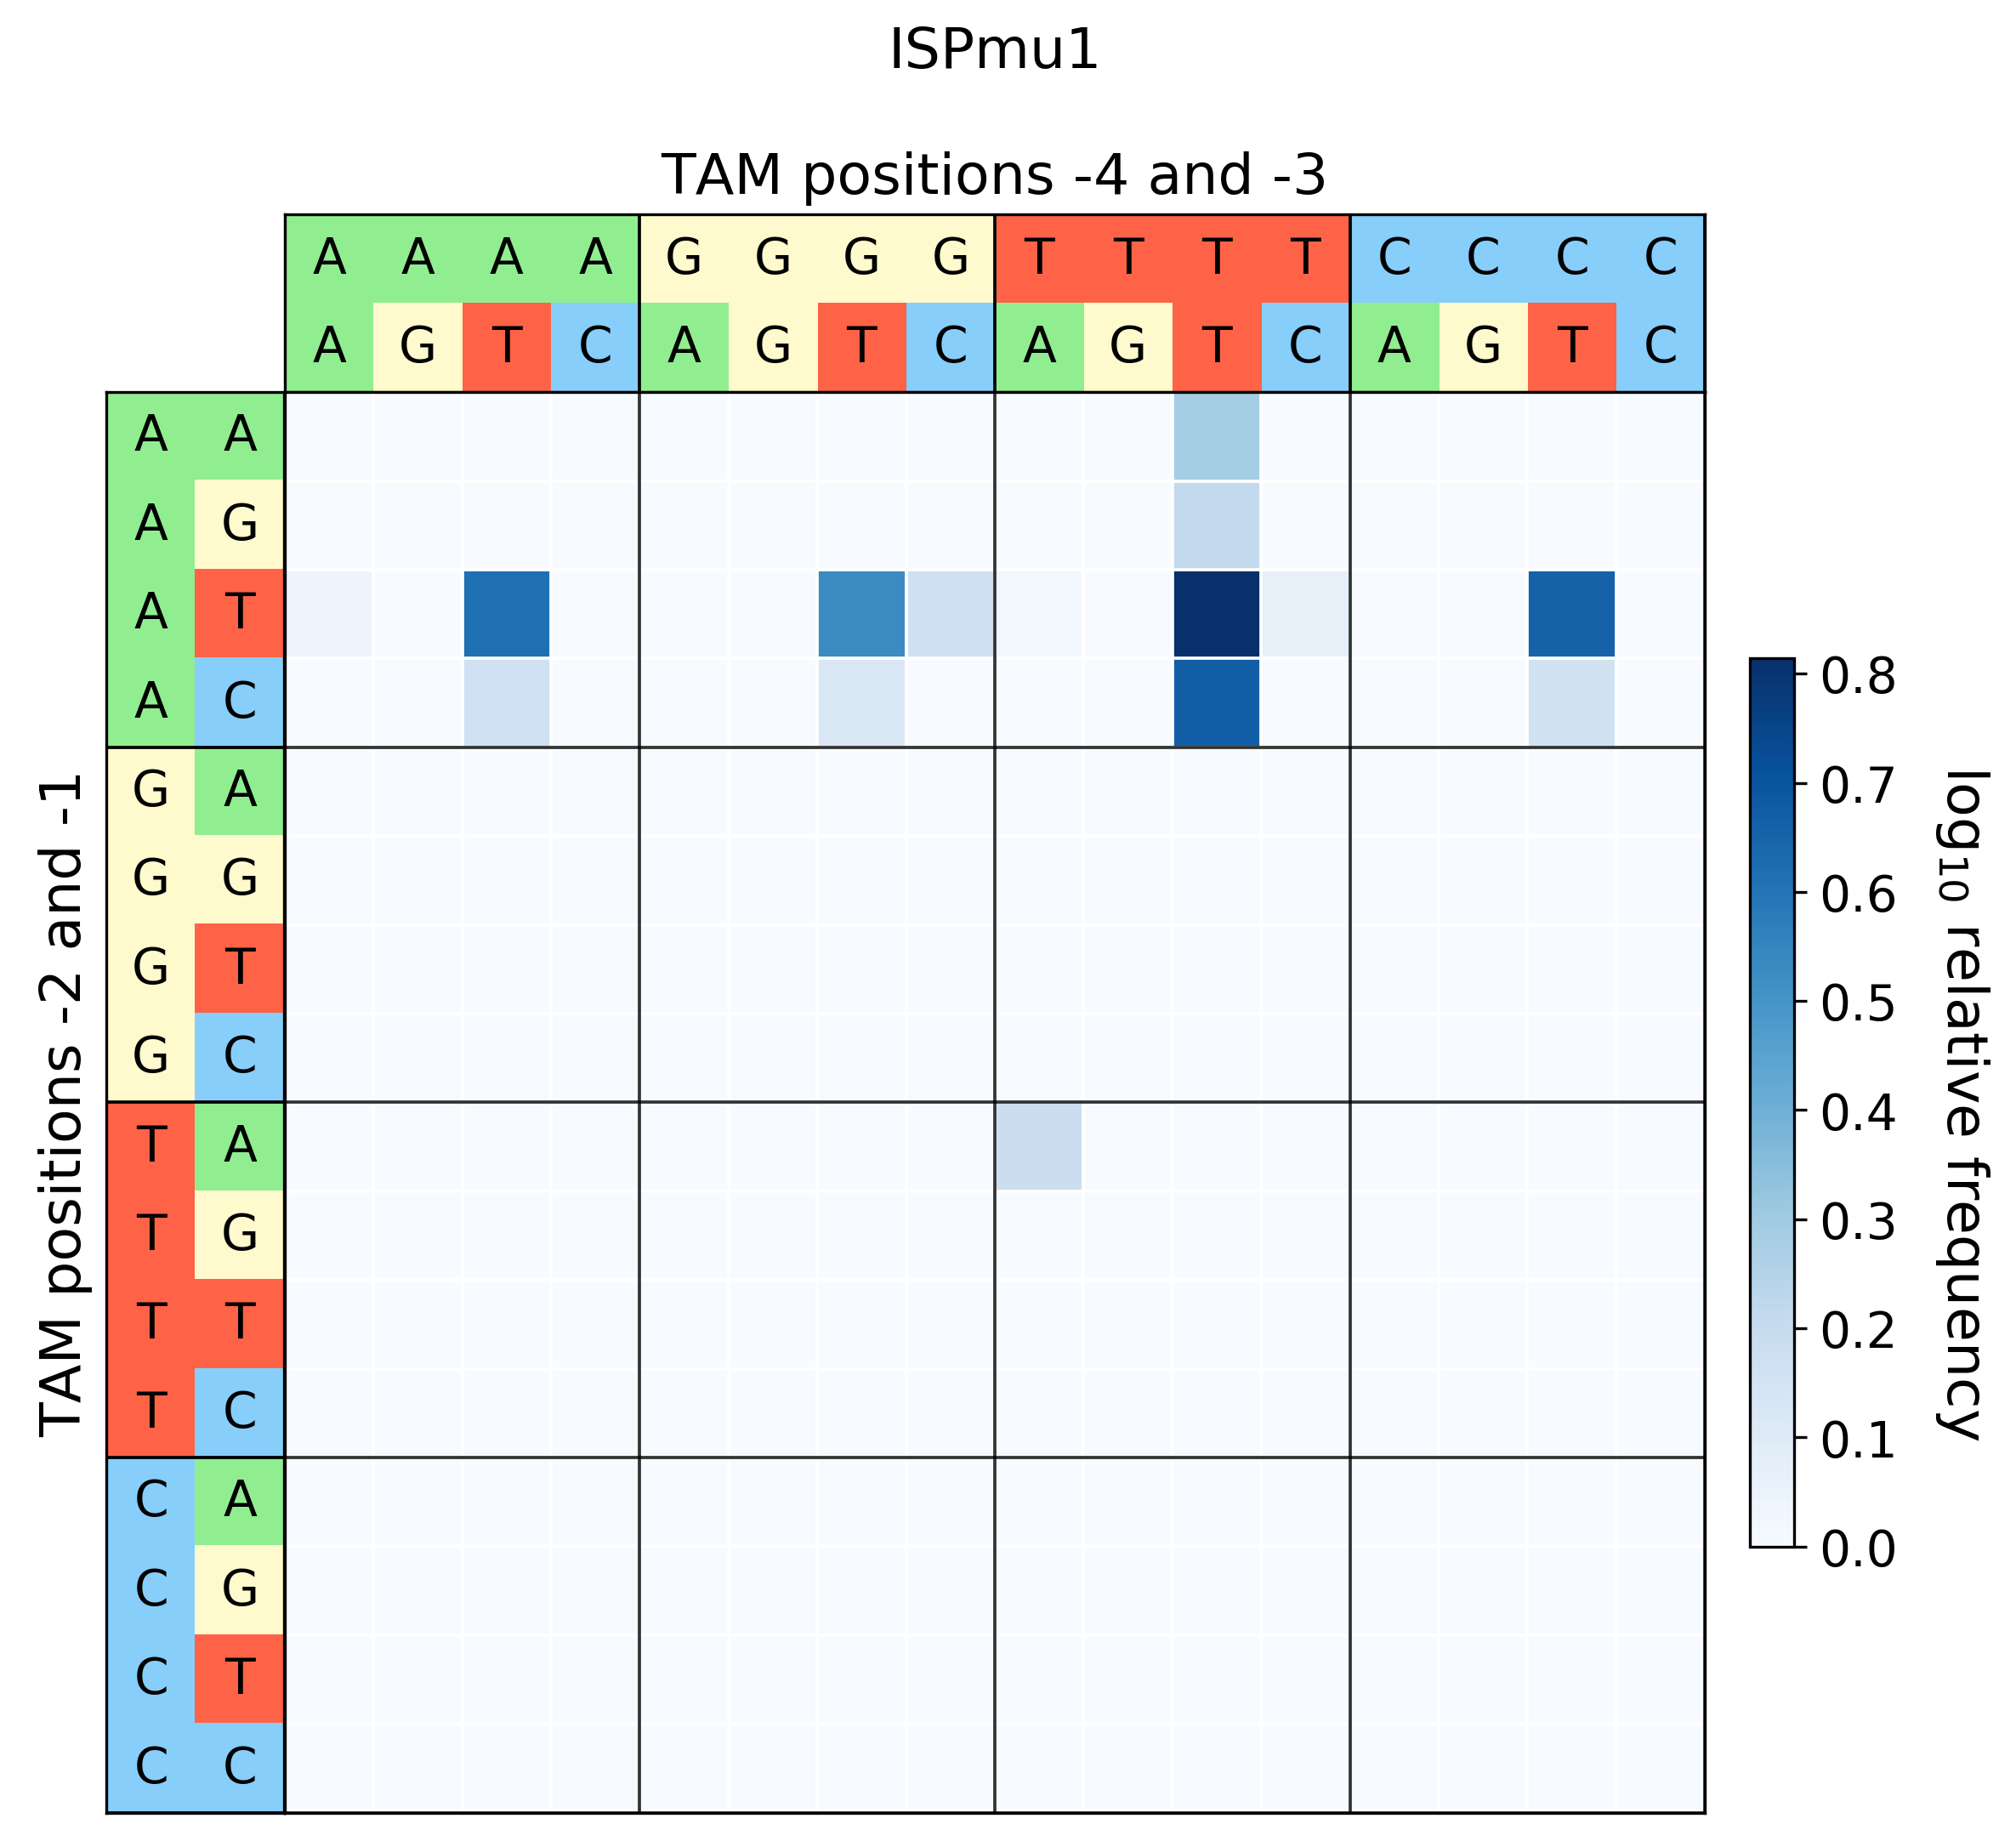

In [79]:
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(8, 8), gridspec_kw={
    'height_ratios': [2, 16], 'width_ratios': [2, 16, 0.5, 0.5]})

axes[0,0].axis('off')
axes[0,2].axis('off')
axes[0,3].axis('off')

ax=axes[0,1]
ax.imshow(col_anno, cmap=base_colormap)
ax.tick_params(bottom=False, labelleft=False, labelbottom=False, left=False)
ax.set_title('{}\n\nTAM positions {} and {}'.format(variant_name, *np.array(colpos)-8), size=16)

for i in range(col_anno.shape[0]):
    for j in range(col_anno.shape[1]):
        text = ax.text(j, i, to_base[col_anno.loc[i, j]], size=14,
                       ha="center", va="center", color="k")

for i in np.arange(4,col_anno.shape[1]+1,4)-.5:
    ax.axvline(x=i, ls='-', color='k', zorder=3, linewidth=0.9)
        

ax=axes[1,0]
ax.imshow(row_anno, cmap=base_colormap)
ax.tick_params(bottom=False, labelleft=False, labelbottom=False, left=False)
ax.set_ylabel('TAM positions {} and {}'.format(*np.array(rowpos)-8), size=16)

for i in range(row_anno.shape[0]):
    for j in range(row_anno.shape[1]):
        text = ax.text(j, i, to_base[row_anno.loc[i, j]], size=14,
                       ha="center", va="center", color="k")

for i in np.arange(4,row_anno.shape[0]+1,4)-.5:
    ax.axhline(y=i, ls='-', color='k', zorder=3, linewidth=0.9)


ax=axes[1,1]
im = ax.imshow(heatmap_data, cmap="Blues")

ax.tick_params(bottom=False, labelleft=False, labelbottom=False, left=False)

#axes[1,1].spines['left'].set_visible(False)

ax.set_xticks(np.arange(1,heatmap_data.shape[1]+1)-.5, minor=False)
ax.set_yticks(np.arange(1,heatmap_data.shape[0]+1)-.5, minor=False)
ax.grid(which="major", color="w", linestyle='-', linewidth=0.9)

for i in np.arange(4,heatmap_data.shape[1]+1,4)-.5:
    ax.axhline(y=i, ls='-', color='k', zorder=3, linewidth=0.9, alpha=0.8)
    ax.axvline(x=i, ls='-', color='k', zorder=3, linewidth=0.9, alpha=0.8)


ax.tick_params(which="minor", bottom=False, left=False)

ax=axes[1,2]
ax.set_aspect(16)
ax.axis('off')

ax=axes[1,3]
ax.set_aspect(20)
cbar = plt.colorbar(im, cax=ax)
cbar.ax.set_ylabel(r'log$_{10}$ relative frequency', size=16,
                   labelpad = 10, rotation=-90, va="bottom")
cbar.ax.tick_params(labelsize=14)

#plt.suptitle('{} TAM'.format(variant_name), size=16)

#plt.subplots_adjust(hspace=-0.1, wspace=0.001)
plt.subplots_adjust(left=0, wspace=0, hspace=0, right=0.827, bottom=0, top=0.783)
#plt.savefig('Heatmaps/{}_TAM.svg'.format(variant_name))
plt.show()

In [71]:
rowpos, colpos = [6,7], [3,4,5]

In [72]:
heatmap_data, rowidx, colidx = make_TAM_array(lrf, rowpos, colpos)

to_int = {'A':0, 'T':1, 'C':2, 'G':3}

to_base = {to_int[k]:k for k in to_int}

col_anno = pd.DataFrame([[to_int[i] for i in list(idx)] for idx in colidx]).transpose()

row_anno = pd.DataFrame([[to_int[i] for i in list(idx)] for idx in rowidx])

base_colormap = ListedColormap(["lightgreen", "tomato", "lightskyblue", "lemonchiffon"])

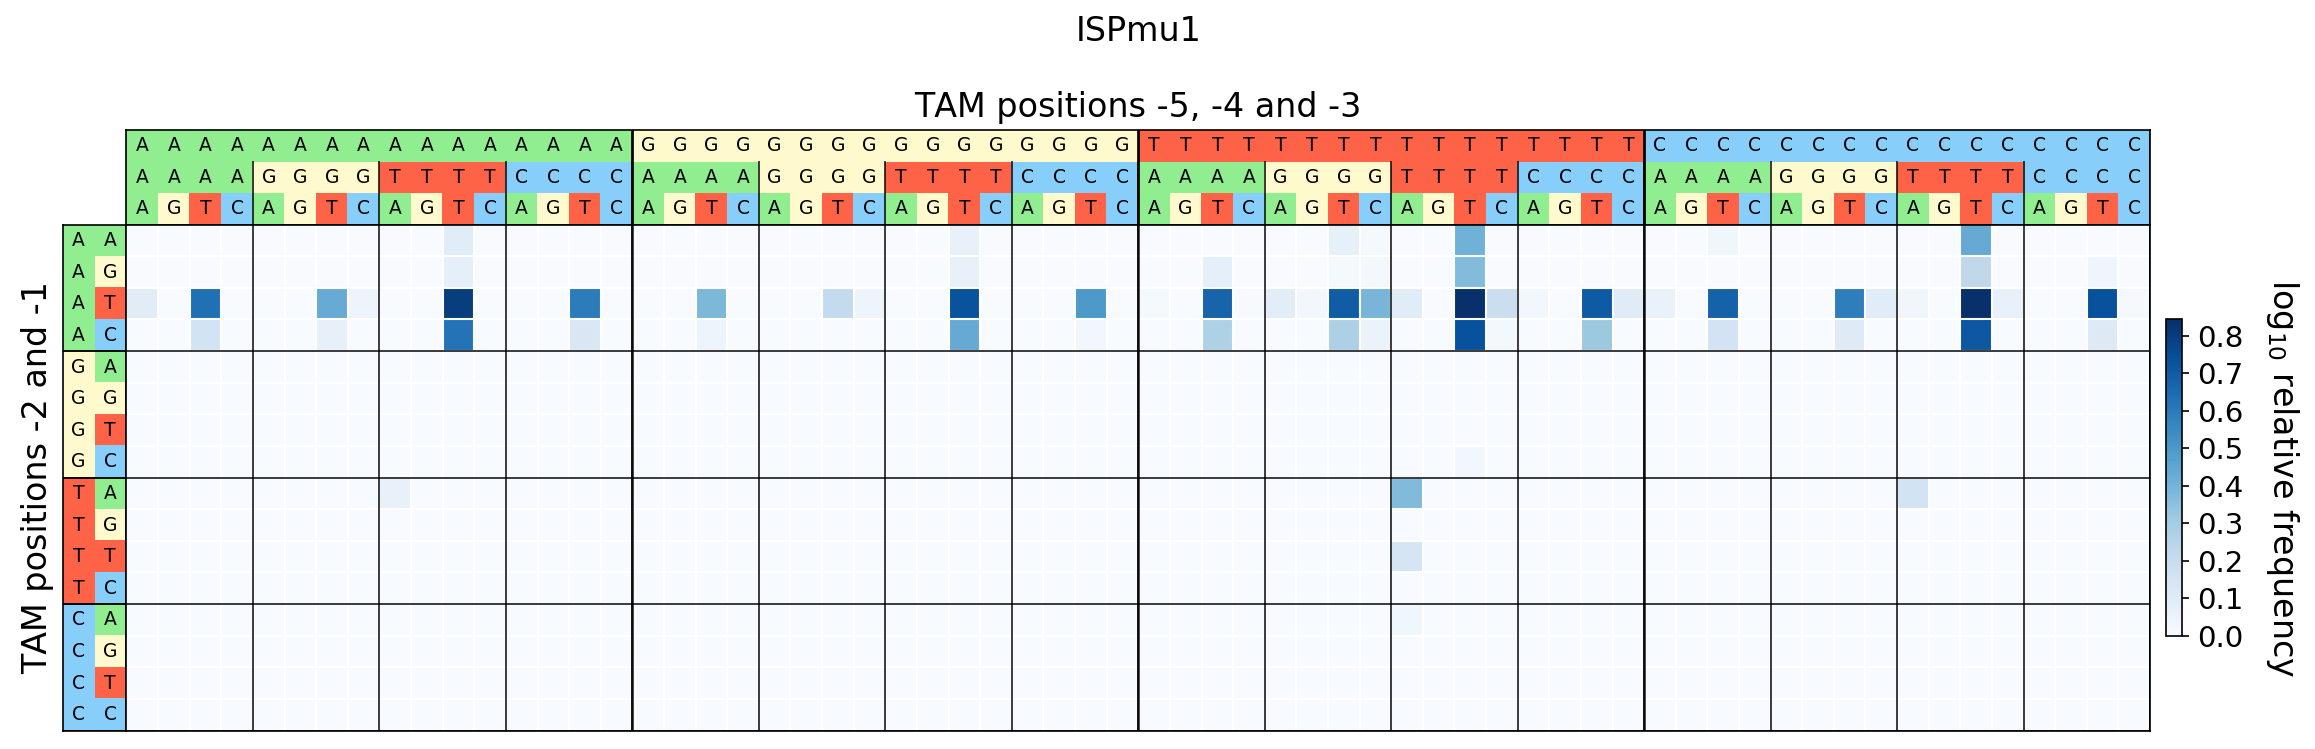

In [74]:
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(18, 5), gridspec_kw={
    'height_ratios': [3, 16], 'width_ratios': [2, 64, 0.5, 0.5]}, dpi=150)

axes[0,0].axis('off')
axes[0,2].axis('off')
axes[0,3].axis('off')

ax=axes[0,1]
ax.imshow(col_anno, cmap=base_colormap)
ax.tick_params(bottom=False, labelleft=False, labelbottom=False, left=False)
ax.set_title('{}\n\nTAM positions {}, {} and {}'.format(variant_name, *np.array(colpos)-8), size=16)

for i in range(col_anno.shape[0]):
    for j in range(col_anno.shape[1]):
        text = ax.text(j, i, to_base[col_anno.loc[i, j]], size=9,
                       ha="center", va="center", color="k")

for i in np.arange(16,col_anno.shape[1]+1,16)-.5:
    ax.axvline(x=i, ls='-', color='k', zorder=3, linewidth=1.3)
    
for i in np.arange(4,heatmap_data.shape[1]+1,4)-.5:
    ax.axvline(x=i, ymin=0, ymax=0.66, ls='-', color='k', zorder=2, linewidth=0.9, alpha=0.8)
        

ax=axes[1,0]
ax.imshow(row_anno, cmap=base_colormap)
ax.tick_params(bottom=False, labelleft=False, labelbottom=False, left=False)
ax.set_ylabel('TAM positions {} and {}'.format(*np.array(rowpos)-8), size=16)

for i in range(row_anno.shape[0]):
    for j in range(row_anno.shape[1]):
        text = ax.text(j, i, to_base[row_anno.loc[i, j]], size=9,
                       ha="center", va="center", color="k")

for i in np.arange(4,row_anno.shape[0]+1,4)-.5:
    ax.axhline(y=i, ls='-', color='k', zorder=3, linewidth=0.9)


ax=axes[1,1]
im = ax.imshow(heatmap_data, cmap="Blues")

ax.tick_params(bottom=False, labelleft=False, labelbottom=False, left=False)

#axes[1,1].spines['left'].set_visible(False)

ax.set_xticks(np.arange(1,heatmap_data.shape[1]+1)-.5, minor=False)
ax.set_yticks(np.arange(1,heatmap_data.shape[0]+1)-.5, minor=False)
ax.grid(which="major", color="w", linestyle='-', linewidth=1)

for i in np.arange(16,heatmap_data.shape[1]+1,16)-.5:
    ax.axvline(x=i, ls='-', color='k', zorder=3, linewidth=1.3, alpha=0.8)
    
for i in np.arange(4,heatmap_data.shape[1]+1,4)-.5:
    ax.axvline(x=i, ls='-', color='k', zorder=2, linewidth=0.9, alpha=0.8)

for i in np.arange(4,heatmap_data.shape[0]+1,4)-.5:
    ax.axhline(y=i, ls='-', color='k', zorder=3, linewidth=0.9, alpha=0.8)


ax.tick_params(which="minor", bottom=False, left=False)

ax=axes[1,2]
ax.set_aspect(16)
ax.axis('off')

ax=axes[1,3]
ax.set_aspect(20)
cbar = plt.colorbar(im, cax=ax)
cbar.ax.set_ylabel(r'log$_{10}$ relative frequency', size=16,
                   labelpad = 10, rotation=-90, va="bottom")
cbar.ax.tick_params(labelsize=14)

#plt.suptitle('{} TAM'.format(variant_name), size=16)

plt.subplots_adjust(left=0, wspace=0, hspace=0, right=0.785, bottom=0, top=0.801)
#plt.savefig('Heatmaps/{}_TAM_5.svg'.format(variant_name))
plt.show()